# Chatbot generativo en español con Seq2Seq

**Alberto Aragón Jiménez** · Ingeniería Informática (Computación y Sistemas Inteligentes), Universidad de Granada

Este notebook recorre el proyecto paso a paso: el dataset, el modelo, el entrenamiento de la versión final y la comparación entre las cuatro versiones que he probado.

El punto de partida fue un chatbot Seq2Seq con LSTM que hice para la asignatura de Aprendizaje Automático. Funcionaba con las frases que había visto, pero fallaba en cuanto la pregunta se formulaba con otras palabras. Aquí intento arreglar eso con dos mejoras: **atención** y **embeddings preentrenados en español**.

El código está en `src/chatbot/`; el notebook solo lo usa y explica los resultados.

In [1]:
import os
import sys
import warnings

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore")
sys.path.insert(0, "../src")

import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from chatbot.data import cargar_intenciones, pares, aumentar, respuestas_validas
from chatbot.text import tokenizar
from chatbot.bot import Chatbot

## 1. El dataset

El dataset está organizado por **intenciones**: saludar, despedirse, preguntar la hora, preguntar qué es el encoder... Cada intención tiene una o varias respuestas válidas y varias formas de preguntar lo mismo, repartidas en cuatro grupos:

- **train**: frases para entrenar.
- **val**: una frase por intención, para decidir cuándo parar el entrenamiento.
- **test**: tres frases por intención que el modelo no ve nunca, pero que comparten alguna palabra clave con las de entrenamiento.
- **hard**: dos frases por intención **sin ninguna palabra de contenido en común** con las de entrenamiento. Es la prueba difícil: el modelo solo puede acertar si entiende el significado.

In [2]:
intenciones = cargar_intenciones()

resumen = pd.DataFrame({
    split: [len(datos[split]) for datos in intenciones.values()]
    for split in ["train", "val", "test", "hard"]
}, index=list(intenciones)).sum()

print("Intenciones:", len(intenciones))
print(resumen.to_string())

print("\nEjemplo, intención 'ayuda':")
for split in ["train", "test", "hard"]:
    print(f"  {split:5}: {intenciones['ayuda'][split][:3]}")

Intenciones: 24
train    162
val       24
test      72
hard      48

Ejemplo, intención 'ayuda':
  train: ['¿Me ayudas?', 'Necesito ayuda', 'Puedes ayudarme']
  test : ['¿Me puedes ayudar con algo?', 'Tengo otra pregunta', 'Ayúdame']
  hard : ['Me echas una mano', 'Quería consultarte algo']


Las frases de `hard` están pensadas para que no se puedan acertar copiando palabras. Por ejemplo, `Me echas una mano` no comparte ninguna palabra importante con `Necesito ayuda` o `Puedes ayudarme`.

Como el dataset es pequeño, al entrenamiento se le aplica el mismo **aumento de datos** que en la primera versión: a cada frase se le pone una muletilla delante, una coletilla detrás o se le quita una palabra.

In [3]:
train = aumentar(pares(intenciones, "train"), n_copias=3)
val = pares(intenciones, "val")
test = pares(intenciones, "test")
hard = pares(intenciones, "hard")

print("Frases de entrenamiento después del aumento:", len(train))
print("Ejemplos de frases nuevas:", [f for f, _, _ in train[162:167]])

Frases de entrenamiento después del aumento: 648
Ejemplos de frases nuevas: ['hola chatbot', 'perdona hola', 'hola', 'hola amigo chatbot', 'hola amigo chatbot']


## 2. El modelo

La arquitectura base es la misma de la primera versión: un **encoder** (Embedding + LSTM) que resume la pregunta y un **decoder** (Embedding + LSTM + Dense) que escribe la respuesta palabra a palabra. Sobre ella se pueden activar dos mejoras:

**Atención.** Sin atención, toda la pregunta tiene que caber en los dos vectores de estado del encoder. Con atención, en cada paso el decoder vuelve a mirar todas las palabras de la pregunta y decide en cuáles fijarse.

**Embeddings preentrenados.** En la primera versión cada palabra empezaba con un vector aleatorio y el modelo solo aprendía las palabras de entrenamiento: cualquier palabra nueva se convertía en `<unk>`. Ahora el encoder usa los vectores de spaCy (`es_core_news_md`), entrenados con millones de textos en español. El vocabulario pasa de unas 170 palabras a unas 350.000, y palabras parecidas tienen vectores parecidos. Los vectores se dejan **congelados**: si se ajustaran, el modelo movería solo las palabras de entrenamiento y las nuevas dejarían de estar cerca de ellas.

In [4]:
from chatbot.vocab import VocabularioPreentrenado

vocab = VocabularioPreentrenado(pares(intenciones, "train"))
print("Palabras en el vocabulario del encoder:", f"{len(vocab.stoi):,}")
print("Palabras de entrenamiento que spaCy no conoce:", vocab.palabras_extra)

# ¿Qué palabras conocidas se parecen a una palabra que el chatbot nunca ha visto?
import numpy as np
palabras_train = sorted({t for f, _, _ in pares(intenciones, "train") for t in tokenizar(f)})
for nueva in ["define", "aprendes", "chistes", "tormenta"]:
    v = vocab.matriz[vocab.stoi[nueva]]
    similitud = {p: float(vocab.matriz[vocab.stoi[p]] @ v) for p in palabras_train if p != nueva}
    cercanas = sorted(similitud, key=similitud.get, reverse=True)[:4]
    print(f"{nueva:11} -> {cercanas}")

Palabras en el vocabulario del encoder: 351,492
Palabras de entrenamiento que spaCy no conoce: 8
define      -> ['explicas', 'significa', 'funciona', 'explicame']
aprendes    -> ['aprender', 'aprendiste', 'aprendido', 'sabes']
chistes     -> ['chiste', 'reir', 'dices', 'hablar']
tormenta    -> ['llover', 'noche', 'frio', 'llamas']


Ninguna de estas cuatro palabras aparece en las frases de entrenamiento, pero sus vectores están cerca de palabras que sí aparecen. Para el modelo original las tres eran simplemente `<unk>`.

## 3. Entrenamiento de la versión final

Elegí la versión final con el conjunto de **validación** (no con el test): atención + embeddings preentrenados, que es la que mejor resultado daba en validación. Se entrena con early stopping: el entrenamiento se para cuando la pérdida de validación deja de mejorar durante 25 épocas y se recuperan los mejores pesos.

In [5]:
bot = Chatbot(atencion=True, preentrenado=True, semilla=0)
bot.entrenar(train, val)

print("Épocas entrenadas:", len(bot.historial["loss"]))
print("Parámetros entrenables:", f"{bot.n_parametros():,}")

Épocas entrenadas: 43
Parámetros entrenables: 369,309


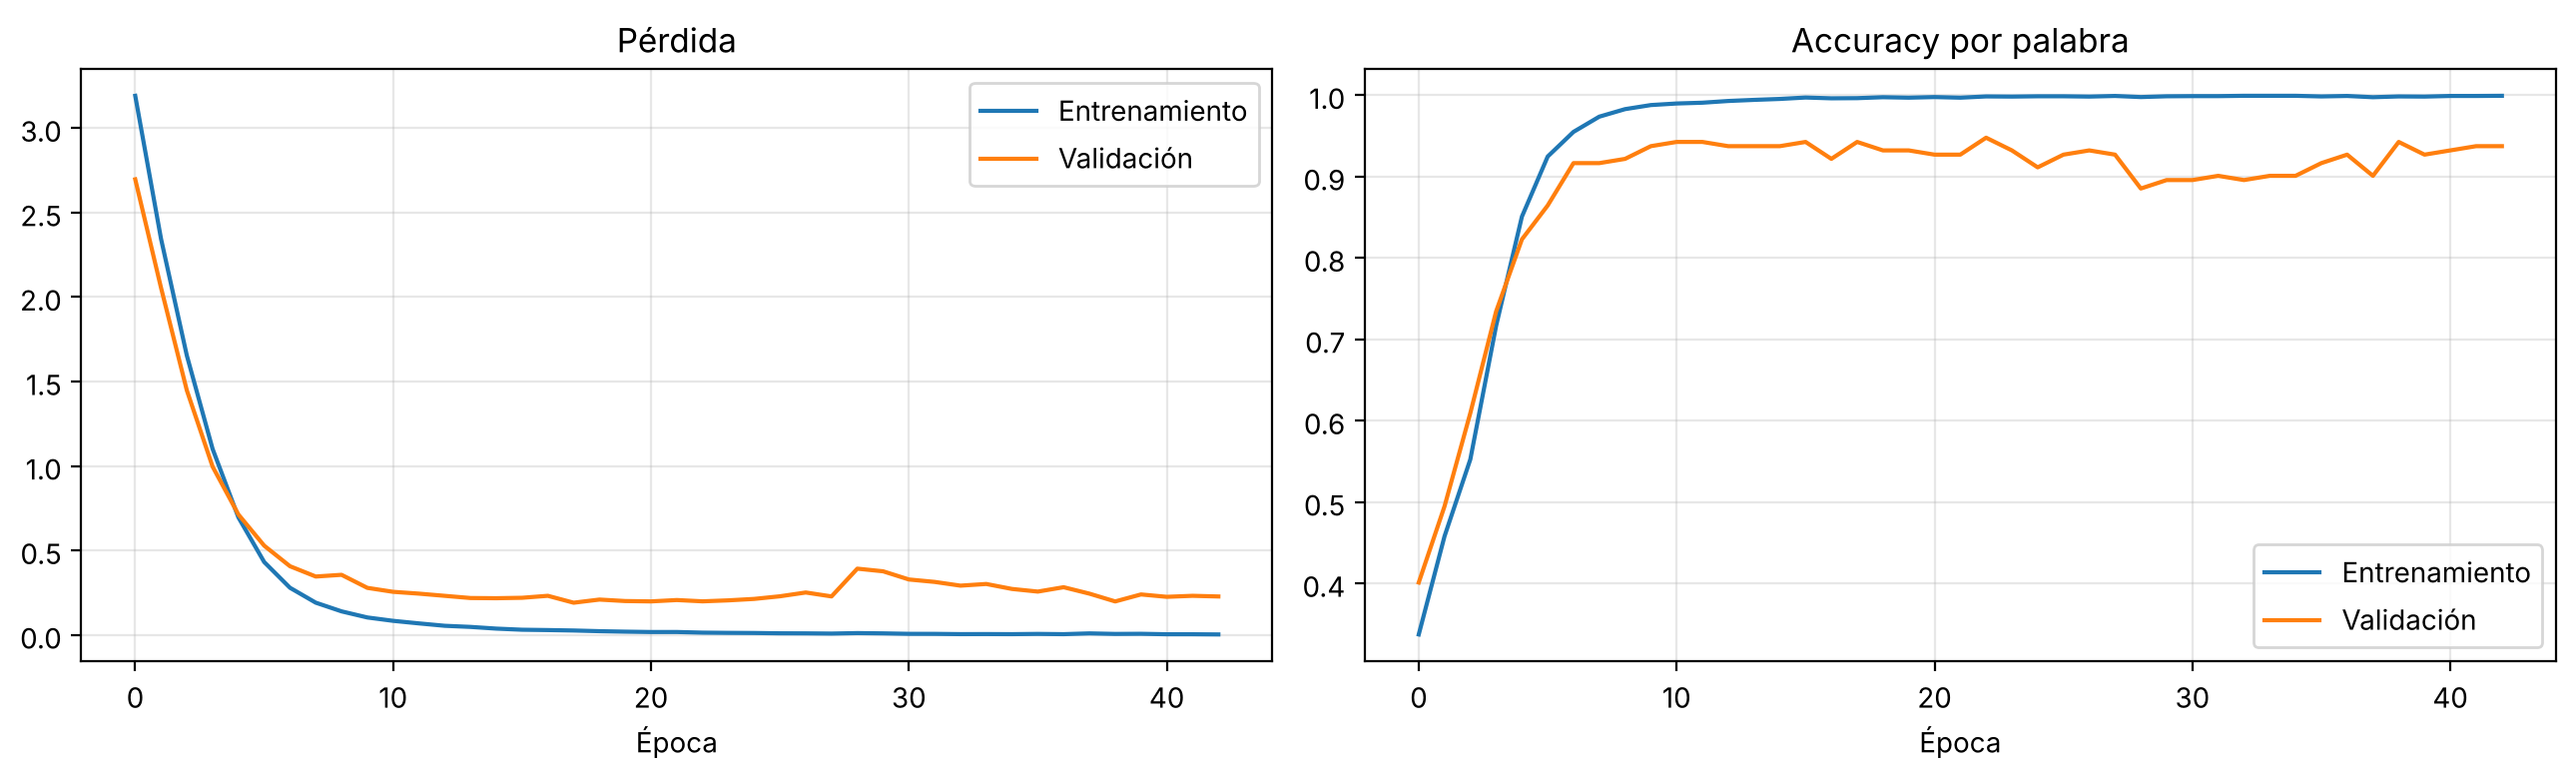

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(bot.historial["loss"], label="Entrenamiento")
axes[0].plot(bot.historial["val_loss"], label="Validación")
axes[0].set_title("Pérdida")

axes[1].plot(bot.historial["accuracy"], label="Entrenamiento")
axes[1].plot(bot.historial["val_accuracy"], label="Validación")
axes[1].set_title("Accuracy por palabra")

for ax in axes:
    ax.set_xlabel("Época")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

La pérdida de validación baja junto con la de entrenamiento y después se estabiliza; el early stopping corta ahí. La accuracy de estas gráficas es por palabra generada, no por respuesta completa. La métrica que importa viene después: si la respuesta entera es correcta.

In [7]:
validas = respuestas_validas(intenciones)

def evaluar(bot, lista):
    respuestas = bot.responder_lote([frase for frase, _, _ in lista])
    return pd.DataFrame({
        "Frase": [frase for frase, _, _ in lista],
        "Intención": [intencion for _, _, intencion in lista],
        "Respuesta": respuestas,
        "Correcta": [r in validas[i] for r, (_, _, i) in zip(respuestas, lista)],
    })

res_test = evaluar(bot, test)
res_hard = evaluar(bot, hard)
print(f"Test: {res_test.Correcta.sum()} de {len(res_test)} ({res_test.Correcta.mean():.0%})")
print(f"Hard: {res_hard.Correcta.sum()} de {len(res_hard)} ({res_hard.Correcta.mean():.0%})")

display(res_hard[res_hard.Correcta])

Test: 65 de 72 (90%)
Hard: 7 de 48 (15%)


,Frase,Intención,Respuesta,Correcta
7,¿Cómo lo llevas?,estado,estoy funcionando correctamente,True
15,¿En qué trabajas?,actividad,aprendiendo a hablar,True
19,Quería consultarte algo,ayuda,si dime tu pregunta,True
28,¿De qué estás construido?,funcionamiento,uso una red seq2seq con lstm,True
31,¿Quién te enseñó?,entrenamiento,aprendi con ejemplos de preguntas y respuestas,True
45,¿Cómo pasas el texto a números?,embedding,convierte cada palabra en un vector,True
47,¿Por qué aprender de memoria es malo?,sobreajuste,es memorizar en vez de generalizar,True


## 4. ¿Qué mejora ha servido?

Para comparar las versiones de forma justa, cada una se entrena **cinco veces con semillas distintas** (`python -m chatbot.experiments`) y se da la media. Con datasets tan pequeños, una sola ejecución puede engañar: dos semillas del mismo modelo pueden diferir varios puntos.

También incluyo una referencia que no genera texto: buscar la frase de entrenamiento más parecida (media de los vectores de spaCy) y devolver su respuesta.

acierto_val        acierto_test         \
                                    mean    std         mean    std   
version                                                               
retrieval_baseline                 0.708    NaN        0.694    NaN   
seq2seq                            0.717  0.062        0.803  0.015   
seq2seq_attention                  0.783  0.019        0.769  0.036   
seq2seq_pretrained                 0.750  0.059        0.956  0.018   
seq2seq_attention_pretrained       0.850  0.048        0.933  0.028   

                             acierto_hard        epocas          
                                     mean    std   mean     std  
version                                                          
retrieval_baseline                  0.083    NaN    0.0     NaN  
seq2seq                             0.108  0.017   49.2   6.221  
seq2seq_attention                   0.100  0.027   59.2  14.342  
seq2seq_pretrained                  0.158  0.019   53.2  24.530  
seq2seq_attention_pretrained        0.125  0.047   79.6  38.850

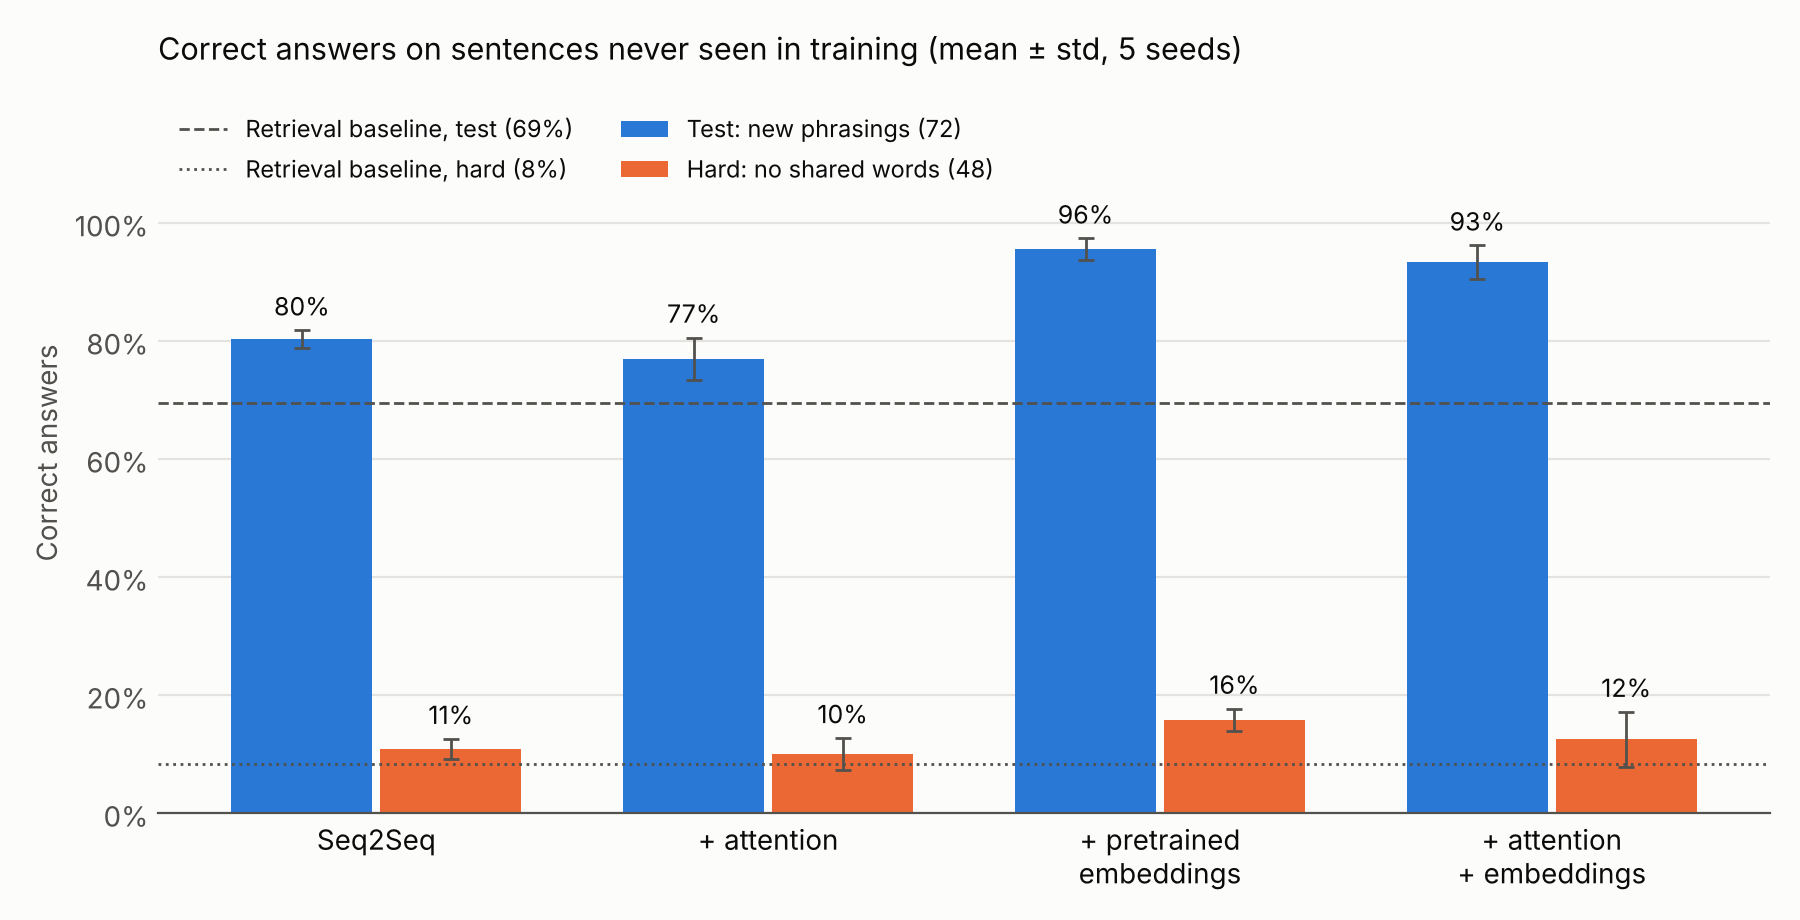

In [8]:
metricas = pd.read_csv("../results/metrics.csv")

tabla = (metricas.groupby("version", sort=False)[["acierto_val", "acierto_test", "acierto_hard", "epocas"]]
         .agg(["mean", "std"]).round(3))
display(tabla)
display(Image("../figures/results.png", width=800))

Lo que dicen los números:

- **Los embeddings preentrenados son la mejora que funciona.** En test el acierto pasa del 80 % al 96 %. Las frases que el modelo original fallaba tenían una palabra que no había visto (`define`, `aprendes`, `gracioso`), que para él era `<unk>`, o una expresión que en entrenamiento solo aparecía en otra intención (`me explicas` solo estaba en *Me lo explicas*, de la intención "no entiendo"). Con los vectores de spaCy, esas palabras se parecen a las que sí conoce y el modelo se fija en la palabra clave de la pregunta.
- **La atención no mejora el acierto aquí.** Las preguntas tienen 3–6 palabras y cada intención depende de una o dos palabras clave, así que los estados finales de la LSTM ya bastan para resumirlas. La atención está pensada para frases largas, como en traducción. Sí sirve para ver en qué se fija el modelo (apartado 5).
- **La validación eligió atención + embeddings** (85 % frente a 75 %), aunque en test la versión sin atención acierta algo más (96 % frente a 93 %). Con 24 frases de validación y estas desviaciones, la diferencia entre las dos está dentro del ruido. No cambio la elección mirando el test, porque entonces el test dejaría de ser una medida honesta.
- **Las frases `hard` siguen siendo muy difíciles**: como mucho un 16 %. Los vectores de palabras ayudan cuando hay una palabra cercana a alguna conocida (`construido` se parece a `hecho` y `arquitectura`, así que *¿De qué estás construido?* se entiende), pero no entienden frases enteras: `Me echas una mano` sigue sin parecerse a `Necesito ayuda`.
- **Generar es mejor que buscar la frase más parecida**: la referencia por recuperación se queda en el 69 % en test y el 8 % en hard. Hacer la media de los vectores de una frase pierde demasiada información.

In [9]:
predicciones = pd.read_csv("../results/predictions.csv")
test_pred = predicciones[predicciones.split == "test"]

por_frase = test_pred.pivot_table(index="frase", columns="version", values="correcta", aggfunc="mean")
arregladas = por_frase[(por_frase.seq2seq < 0.5) & (por_frase.seq2seq_pretrained >= 0.8)]

print("Frases de test que el Seq2Seq base falla y la versión con embeddings acierta:")
display(arregladas[["seq2seq", "seq2seq_pretrained"]].rename(
    columns={"seq2seq": "Base", "seq2seq_pretrained": "Con embeddings"}))

Frases de test que el Seq2Seq base falla y la versión con embeddings acierta:


version,Base,Con embeddings
frase,,
Define atención,0.0,1.0
Define embedding,0.0,1.0
Dime algo gracioso,0.0,0.8
Me explicas Seq2Seq,0.0,1.0
Me explicas el decoder,0.4,1.0
Me explicas el encoder,0.2,1.0
Me explicas el sobreajuste,0.0,1.0
Me explicas la atención,0.2,1.0
Me explicas qué es LSTM,0.0,1.0


## 5. Dónde mira la atención

Cada fila es una palabra de la respuesta y cada columna una palabra de la pregunta. Cuanto más oscuro, más se fija el decoder en esa palabra al escribir.

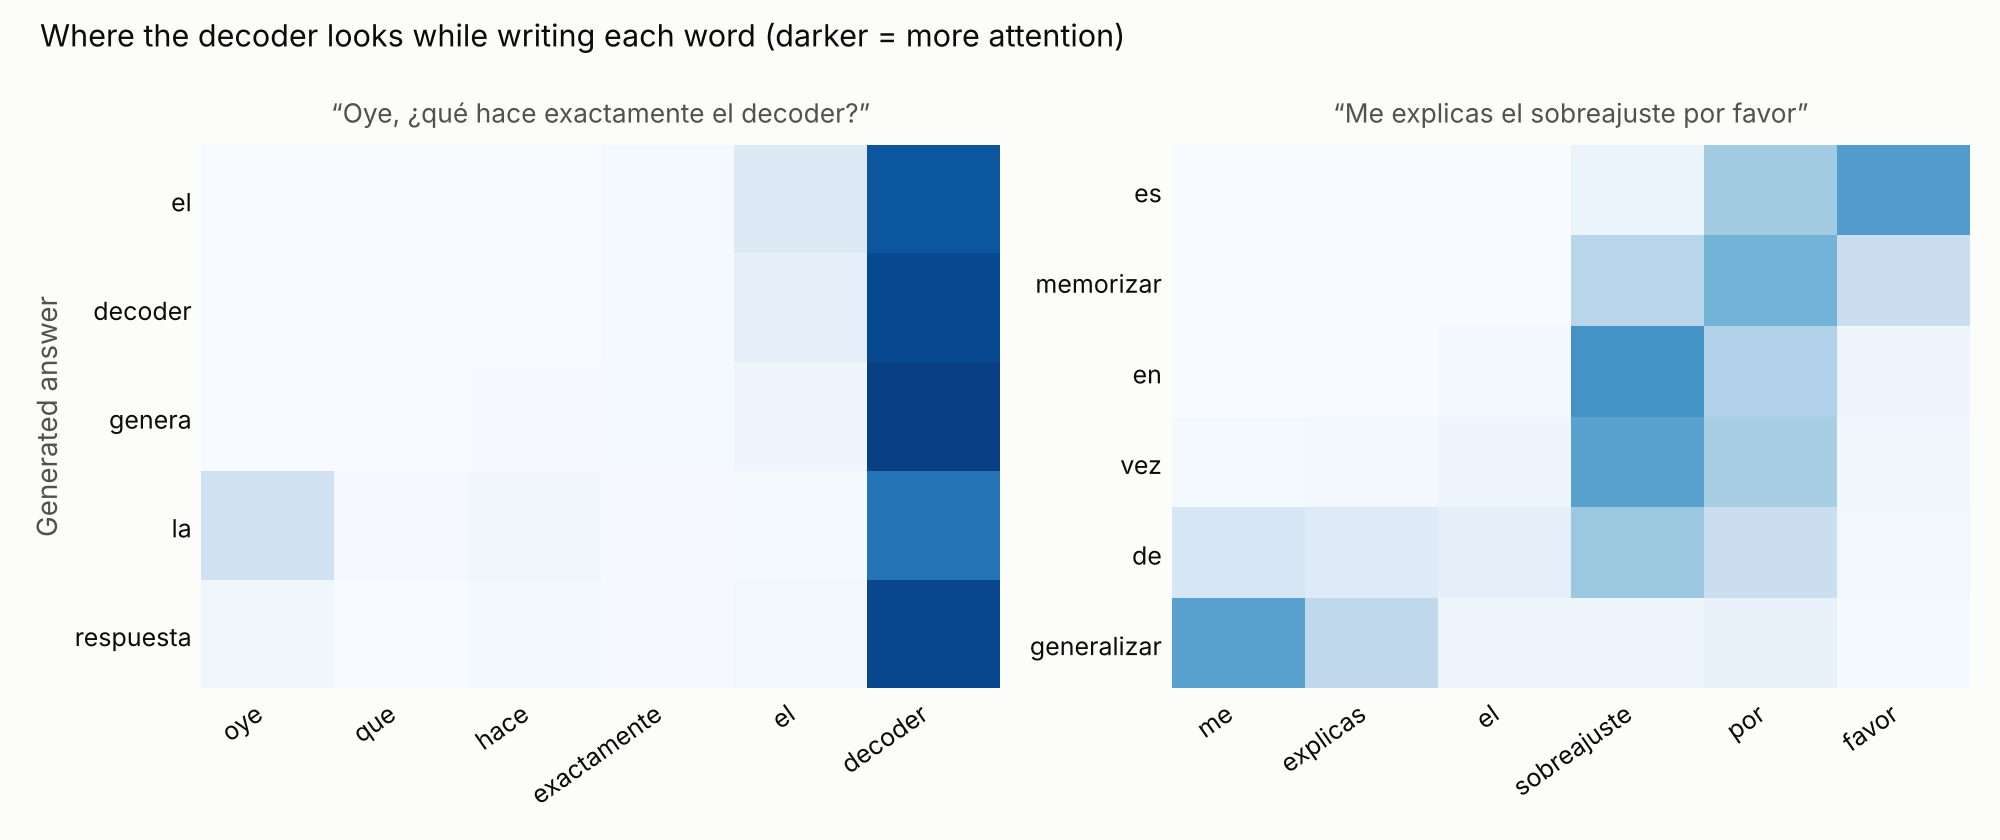

In [10]:
display(Image("../figures/attention.png", width=850))

En la primera frase el modelo ignora `oye`, `que`, `hace` y `exactamente` y se fija casi solo en `decoder`, que es la única palabra que decide la respuesta. En la segunda se reparte entre `sobreajuste` y `por favor`: la coletilla viene del aumento de datos y el modelo ha aprendido a tenerla en cuenta, aunque no aporta significado.

## 6. Prueba libre

In [11]:
frases = [
    "Hola",
    "¿Cómo funcionas?",
    "Me explicas el encoder",
    "¿Qué es el sobreajuste?",
    "Cuéntame un chiste",
    "¿Me echas una mano?",
    "Me marcho ya",
]

for frase, respuesta in zip(frases, bot.responder_lote(frases)):
    print(f"Tú:  {frase}")
    print(f"Bot: {respuesta}\n")

Tú:  Hola
Bot: hola en que puedo ayudarte

Tú:  ¿Cómo funcionas?
Bot: uso un modelo encoder decoder

Tú:  Me explicas el encoder
Bot: el encoder resume la frase de entrada

Tú:  ¿Qué es el sobreajuste?
Bot: es memorizar en vez de generalizar

Tú:  Cuéntame un chiste
Bot: los chistes no son lo mio

Tú:  ¿Me echas una mano?
Bot: que descanses

Tú:  Me marcho ya
Bot: que descanses



## 7. Conclusiones y siguientes pasos

- El cambio que más ha mejorado el chatbot no ha sido hacer el modelo más complejo, sino **darle conocimiento previo del idioma**: con los mismos datos y casi la misma arquitectura, el acierto en frases nuevas sube del 80 % al 96 %.
- La atención no mejora el acierto con frases tan cortas, pero hace el modelo más interpretable.
- El límite está en las frases que dicen lo mismo con palabras totalmente distintas. Para eso no bastan vectores de palabras sueltas: haría falta un modelo que represente **frases completas** (sentence embeddings) o un **Transformer preentrenado** en español, que ya trae ese conocimiento.
- Otra mejora clara sería tener **más datos reales**: 162 frases de entrenamiento para 24 intenciones es muy poco.